# A Catholic Introduction to Artificial Intelligence
## Final Project — Module 4: Bias Auditing & Fairness Analysis
### Classes 7 & 8

---

> *"When AI systems present themselves as neutral and objective, they end up reflecting and reinforcing the stereotypes or ideological bias of their designers and developers... The exclusion of the vulnerable becomes cloaked in a veneer of neutrality and objectivity, against which it becomes difficult to raise objections. In this way, injustice goes unnoticed."*
> — Pope Leo XIV, *Magnifica Humanitas*, no. 102–103

---

## Module Overview

In Module 3, you discovered a striking problem: a model that was 86% accurate caught only 1 of the 14 late submissions it was designed to identify.

This module uses a **larger version of the dataset**: 1,500 records from 150 students, instead of 500. Real data scientists gather more data and check whether their findings hold up. As you work, watch whether Module 3's main lesson still holds: does the model beat guessing, and does it catch the late students?

This module also goes deeper — investigating whether the model's errors are distributed **equally** across all students and assignment types, or whether they concentrate disproportionately on particular groups.

This is called a **bias audit**. It is one of the most important steps in responsible AI development, and it is one that many real-world AI systems skip entirely.

A model that is 90% accurate for some groups and 60% accurate for others may look fine in aggregate statistics while causing serious harm to the groups it serves worst. Those groups are often — not coincidentally — the groups that were already underrepresented in the training data or disadvantaged in the real world.

### What You Will Do in This Module

1. Rebuild and fully document the model pipeline from Module 3
2. Conduct a structured bias audit across multiple dimensions
3. Measure performance disparities quantitatively
4. Investigate the root causes of those disparities
5. Evaluate what the disparities mean ethically — and what, if anything, can be done about them

---

## Setup

This module uses **`synthetic_homework_dataset_v2.csv`**. Put it in the same folder as this notebook before you run the cells below.

In [1]:
# Install the necessary libraries if you haven't already
%pip install pandas numpy scikit-learn matplotlib seaborn

---

## Meet the Data

Before we rebuild the model, let's get to know the new dataset. It has the same 15 columns you worked with in Module 3, but three times as many records. A bigger dataset can tell a different story, so we check the basics first.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv('synthetic_homework_dataset_v2.csv')
print('Rows and columns:', raw.shape)
raw.head()

Rows and columns: (1500, 15)


,student_id,assignment_id,assignment_type,num_questions,difficulty,days_until_due,date_assigned,date_submitted,time_spent_minutes,num_work_sessions,completed_on_time,submitted_late_days,prior_completion_rate,prior_avg_grade,prior_avg_homework_time
0,S207,A39,essay,5,4,9,2026-04-07,2026-04-14,30.6,1,1,0,0.78,93.7,58.6
1,S147,A12,worksheet,18,5,2,2026-01-23,2026-01-25,46.7,1,1,0,1.00,94.1,46.4
2,S124,A7,reading,19,4,1,2026-03-16,2026-03-17,40.2,1,1,0,0.81,95.2,53.8
3,S173,A28,reading,8,1,2,2026-03-25,2026-03-27,15.3,1,1,0,1.00,96.6,65.1
4,S138,A16,essay,9,2,8,2026-03-05,2026-03-14,69.1,2,0,1,0.80,82.0,68.0


In [4]:
# A quick summary of the new dataset
n_late = (raw['completed_on_time'] == 0).sum()
late_rate = n_late / len(raw)

print('=== Dataset at a Glance ===')
print(f'Records:            {len(raw):,}')
print(f'Students:           {raw["student_id"].nunique()} '
      f'({raw.groupby("student_id").size().median():.0f} assignments each)')
print(f'Assignments:        {raw["assignment_id"].nunique()}')
print(f'Dates assigned:     {raw["date_assigned"].min()} to {raw["date_assigned"].max()}')
print(f'Missing values:     {raw.isna().sum().sum()}')
print()
print(f'Late submissions:   {n_late} of {len(raw):,} ({late_rate:.1%})')
print(f'Baseline to beat:   {1 - late_rate:.1%} accuracy by always guessing "on time"')
print()

type_summary = raw.groupby('assignment_type').agg(
    records=('completed_on_time', 'count'),
    late=('completed_on_time', lambda s: (s == 0).sum()),
    late_rate=('completed_on_time', lambda s: round(1 - s.mean(), 3)),
).sort_values('records', ascending=False)
print('=== Records and Late Rate by Assignment Type ===')
print(type_summary.to_string())

=== Dataset at a Glance ===
Records:            1,500
Students:           150 (10 assignments each)
Assignments:        50
Dates assigned:     2026-01-12 to 2026-04-17
Missing values:     0

Late submissions:   319 of 1,500 (21.3%)
Baseline to beat:   78.7% accuracy by always guessing "on time"

=== Records and Late Rate by Assignment Type ===
                 records  late  late_rate
assignment_type                          
essay                450   114      0.253
worksheet            420    96      0.229
coding               270    60      0.222
reading              240    33      0.137
quiz_prep            120    16      0.133


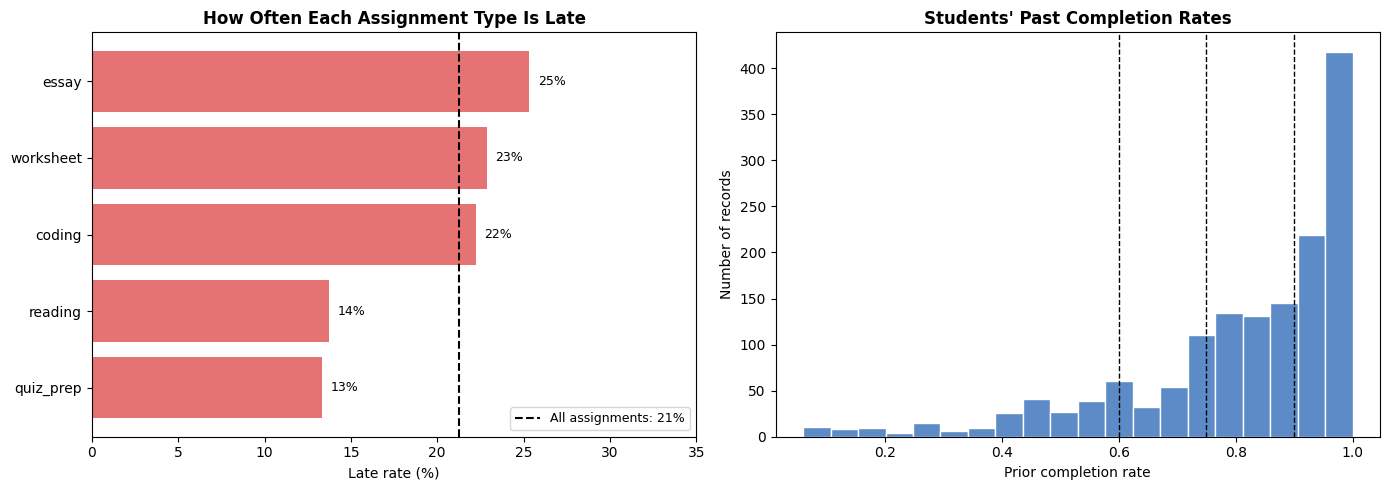

In [8]:
# Two pictures of the new data
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: how often each assignment type is late
late_by_type = (1 - raw.groupby('assignment_type')['completed_on_time'].mean()).sort_values() * 100
axes[0].barh(late_by_type.index, late_by_type.values, color='#E57373')
axes[0].axvline(late_rate * 100, color='black', linestyle='--', linewidth=1.5,
                label=f'All assignments: {late_rate:.0%}')
for i, v in enumerate(late_by_type.values):
    axes[0].text(v + 0.5, i, f'{v:.0f}%', va='center', fontsize=9)
axes[0].set_xlabel('Late rate (%)')
axes[0].set_title('How Often Each Assignment Type Is Late', fontweight='bold')
axes[0].set_xlim(0, 35)
axes[0].legend(fontsize=9)

# Right: students' past records (the dashed lines are the tiers you'll audit in Part 4)
axes[1].hist(raw['prior_completion_rate'], bins=20, color='#5C8BC7', edgecolor='white')
for cut in [0.60, 0.75, 0.90]:
    axes[1].axvline(cut, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Prior completion rate')
axes[1].set_ylabel('Number of records')
axes[1].set_title("Students' Past Completion Rates", fontweight='bold')

plt.tight_layout()
plt.show()

### What to Notice

**How the new dataset compares with Module 3's:**

| | Module 3 dataset | Module 4 dataset (v2) |
|---|---|---|
| Records | 500 | 1,500 |
| Students | 51 | 150 |
| Assignments | 40 | 50 |
| Late submissions | 14% | 21% |
| Accuracy from always guessing "on time" | 86% | 79% |

- **Late work is more common.** About 1 in 5 submissions is late, compared with about 1 in 7 before. That lowers the bar a model has to clear: guessing "on time" every time now scores about 79%, not 86%. Keep that number in mind when you see the model's accuracy.
- **Essays and worksheets dominate.** They make up more than half the records and are late most often, about 1 in 4. Quiz prep and reading are late about half as often.
- **Most students have strong records.** The typical student turned in 87% of past work on time. The histogram is lopsided, though: about 1 in 6 records (236) comes from students below 60%. The dashed lines mark the tiers you'll audit in Part 4, so remember this smaller group.

---

## Rebuilding the Model from Module 3

The next cell repeats Module 3's full pipeline on the new dataset: it adds the engineered features, trains the same logistic regression model, and builds a `results` table of test-set predictions for the audit.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report
)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (11, 5)

# ── Load and prepare ──────────────────────────────────────────────────
df = pd.read_csv('synthetic_homework_dataset_v2.csv',
                 parse_dates=['date_assigned', 'date_submitted'])

df['time_pressure'] = df['difficulty'] / df['days_until_due']

# The student's HABIT of deadline usage, averaged over EARLIER assignments only (same as Module 3).
# deadline_usage is an intermediate step here; it is never used as a feature.
df = df.sort_values(['student_id', 'date_assigned'])
deadline_usage = ((df['date_submitted'] - df['date_assigned']).dt.days
                  / df['days_until_due'])
df['prior_deadline_usage'] = (
    deadline_usage.groupby(df['student_id'])
                  .transform(lambda s: s.shift().expanding().mean())
)
# Each student's first assignment has no history, so fill it with the median
df['prior_deadline_usage'] = df['prior_deadline_usage'].fillna(df['prior_deadline_usage'].median())
df = df.sort_index()   # restore the original row order so the split is unchanged
le = LabelEncoder()
df['assignment_type_enc'] = le.fit_transform(df['assignment_type'])
print('Assignment type encoding:', dict(zip(le.classes_, le.transform(le.classes_))))

# Same feature sets as Module 3
CONSERVATIVE_FEATURES = [
    'num_questions', 'difficulty', 'days_until_due',
    'prior_avg_homework_time', 'time_pressure',
]
FULL_FEATURES = CONSERVATIVE_FEATURES + [
    'prior_completion_rate', 'prior_deadline_usage',
]

TARGET = 'completed_on_time'

# ── Train the model (same settings as Module 3) ───────────────────────
X = df[FULL_FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

# ── Build a rich test dataframe with all original columns ─────────────
results = df.loc[X_test.index].copy()
results['predicted']    = y_pred
results['prob_on_time'] = y_prob.round(4)
results['correct']      = (results['predicted'] == results[TARGET]).astype(int)
results['error_type']   = 'Correct'
results.loc[(results['predicted'] == 1) & (results[TARGET] == 0), 'error_type'] = 'Missed late'
results.loc[(results['predicted'] == 0) & (results[TARGET] == 1), 'error_type'] = 'Wrongly flagged'

overall_acc = accuracy_score(y_test, y_pred)
print(f'\nModel rebuilt. Overall test accuracy: {overall_acc*100:.1f}%')
print(f'Test set size: {len(results)}')
print(f'Error breakdown: {results["error_type"].value_counts().to_dict()}')

Assignment type encoding: {'coding': np.int64(0), 'essay': np.int64(1), 'quiz_prep': np.int64(2), 'reading': np.int64(3), 'worksheet': np.int64(4)}

Model rebuilt. Overall test accuracy: 81.3%
Test set size: 300
Error breakdown: {'Correct': 244, 'Missed late': 49, 'Wrongly flagged': 7}


---

## Part 1: What Is a Bias Audit?

A bias audit asks: **does the model perform equally well for all subgroups?**

"Performance" means different things in different contexts:
- **Overall accuracy** — what fraction of predictions are correct?
- **Late catch rate (recall)** — of all truly late submissions, what fraction does the model identify?
- **False flag rate** — of all on-time submissions, what fraction does the model wrongly label as late?
- **Average predicted probability** — does the model express different levels of confidence for different groups?

A model can be accurate overall while being systematically **inaccurate** for a specific subgroup. When that subgroup is already disadvantaged, the model compounds existing inequality rather than reducing it.

### Audit Dimensions

We will audit the model across four dimensions:

1. **Assignment type** — does the model work equally well for essays, coding tasks, reading, etc.?
2. **Difficulty level** — is the model less accurate for hard assignments?
3. **Prior completion rate tier** — does the model treat students with weaker histories differently?
4. **Individual students** — are some students consistently mislabeled?

Each dimension reveals something different about the model's failure modes.

### Where the Numbers Come From

Every rate above comes from four simple counts. For any group of students, each prediction lands in exactly one of these boxes:

| | Model predicted **late** | Model predicted **on time** |
|---|---|---|
| **Actually late** | Late caught ✅ | Late missed ❌ |
| **Actually on time** | On-time flagged ❌ | On-time correct ✅ |

This grid is called a **confusion matrix**. The audit helper below reports all four counts next to each rate, so you can always check the arithmetic:

- **Accuracy** = (Late caught + On-time correct) ÷ n
- **Late recall** = Late caught ÷ (Late caught + Late missed)
- **False flag rate** = On-time flagged ÷ (On-time flagged + On-time correct)

In [10]:
# Helper functions: compute audit metrics for any subgroup, and show the arithmetic
def audit_group(subset, group_name='Group'):
    """Returns a dict of fairness metrics for a subset of the test data,
    including the four confusion-matrix counts each rate is built from."""
    n = len(subset)
    if n == 0:
        return None

    actual   = subset[TARGET]        # 1 = on time, 0 = late
    predicted = subset['predicted']  # the model's 0/1 call

    # The four confusion-matrix counts
    late_caught     = ((actual == 0) & (predicted == 0)).sum()  # late, flagged late
    late_missed     = ((actual == 0) & (predicted == 1)).sum()  # late, called on time
    ontime_flagged  = ((actual == 1) & (predicted == 0)).sum()  # on time, flagged late
    ontime_correct  = ((actual == 1) & (predicted == 1)).sum()  # on time, called on time

    actual_late   = late_caught + late_missed
    actual_ontime = ontime_flagged + ontime_correct

    # Every rate is one count divided by another
    accuracy        = (late_caught + ontime_correct) / n
    late_recall     = late_caught / actual_late if actual_late > 0 else np.nan
    false_flag_rate = ontime_flagged / actual_ontime if actual_ontime > 0 else np.nan

    return {
        'Group': group_name,
        'n': n,
        'Actual late': int(actual_late),
        'Late caught': int(late_caught),
        'Late missed': int(late_missed),
        'On-time flagged': int(ontime_flagged),
        'On-time correct': int(ontime_correct),
        'Accuracy': round(accuracy, 3),
        'Late recall': round(late_recall, 3),
        'False flag rate': round(false_flag_rate, 3),
        'Avg predicted prob': round(subset['prob_on_time'].mean(), 3),
    }


def show_calculations(audit_rows):
    """Prints each rate as the fraction it was computed from."""
    def frac(top, bottom):
        return f'{top}/{bottom} = {top / bottom:.3f}' if bottom > 0 else 'n/a'

    calc = pd.DataFrame([{
        'Group': r['Group'],
        'Accuracy': frac(r['Late caught'] + r['On-time correct'], r['n']),
        'Late recall': frac(r['Late caught'], r['Actual late']),
        'False flag rate': frac(r['On-time flagged'], r['On-time flagged'] + r['On-time correct']),
    } for r in audit_rows])
    print(calc.to_string(index=False))


print('Audit helper functions defined.')
print('audit_group measures: accuracy, late recall, false flag rate, and avg predicted probability,')
print('plus the four confusion-matrix counts behind them.')
print('show_calculations prints each rate as the fraction it came from.')

Audit helper functions defined.
audit_group measures: accuracy, late recall, false flag rate, and avg predicted probability,
plus the four confusion-matrix counts behind them.
show_calculations prints each rate as the fraction it came from.


---

## Part 2: Audit by Assignment Type

Does the model perform equally well for all types of homework? A model that works well for worksheets but poorly for essays might be reinforcing existing patterns about which kinds of academic work students struggle with.

In [11]:
# Audit across assignment types
type_audit = []
for atype in sorted(results['assignment_type'].unique()):
    subset = results[results['assignment_type'] == atype]
    row = audit_group(subset, atype)
    if row:
        type_audit.append(row)

# Add overall row
overall = audit_group(results, 'OVERALL')
type_audit.append(overall)

type_df = pd.DataFrame(type_audit)
print('=== Audit by Assignment Type ===')
print(type_df.to_string(index=False))

=== Audit by Assignment Type ===
    Group   n  Actual late  Late caught  Late missed  On-time flagged  On-time correct  Accuracy  Late recall  False flag rate  Avg predicted prob
   coding  50           14            3           11                1               35     0.760        0.214            0.028               0.809
    essay 104           23            6           17                4               77     0.798        0.261            0.049               0.749
quiz_prep  28            3            0            3                0               25     0.893        0.000            0.000               0.864
  reading  44            4            1            3                0               40     0.932        0.250            0.000               0.896
worksheet  74           20            5           15                2               52     0.770        0.250            0.037               0.769
  OVERALL 300           64           15           49                7              22

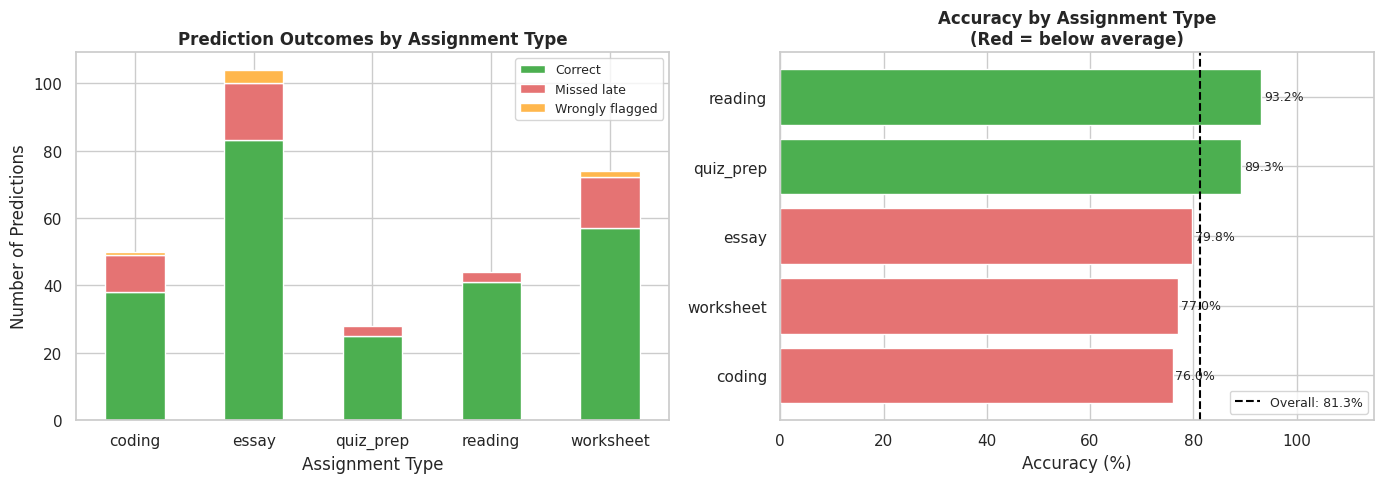

In [12]:
# Visualize accuracy and error types by assignment type
type_counts = results.groupby(['assignment_type', 'error_type']).size().unstack(fill_value=0)
# Ensure all columns exist
for col in ['Correct', 'Missed late', 'Wrongly flagged']:
    if col not in type_counts.columns:
        type_counts[col] = 0
type_counts = type_counts[['Correct', 'Missed late', 'Wrongly flagged']]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: stacked error bars
type_counts.plot(
    kind='bar', stacked=True, ax=axes[0],
    color=['#4CAF50', '#E57373', '#FFB74D'],
    edgecolor='white'
)
axes[0].set_title('Prediction Outcomes by Assignment Type', fontweight='bold')
axes[0].set_xlabel('Assignment Type')
axes[0].set_ylabel('Number of Predictions')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(loc='upper right', fontsize=9)

# Right: accuracy by type with overall reference line
acc_by_type = results.groupby('assignment_type')['correct'].mean().sort_values()
colors = ['#E57373' if v < overall_acc else '#4CAF50' for v in acc_by_type.values]
axes[1].barh(acc_by_type.index, acc_by_type.values * 100, color=colors)
axes[1].axvline(overall_acc * 100, color='black', linestyle='--', linewidth=1.5,
                label=f'Overall: {overall_acc*100:.1f}%')
axes[1].set_xlabel('Accuracy (%)')
axes[1].set_title('Accuracy by Assignment Type\n(Red = below average)', fontweight='bold')
axes[1].set_xlim(0, 115)
for i, (_, v) in enumerate(acc_by_type.items()):
    axes[1].text(v * 100 + 0.5, i, f'{v*100:.1f}%', va='center', fontsize=9)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

### Finding 1: The Highest Accuracy Comes Where There Is the Least to Catch

Reading assignments have the highest accuracy (93.2%), and quiz prep is close behind (89.3%). That sounds impressive until you look at the **Actual late** column in the audit table printed above the charts: only 4 of 44 reading assignments and 3 of 28 quiz-prep assignments were late. The model caught none of the 3 late quiz-prep assignments (a **Late recall** of 0.000) and still scored 89%.

Coding and worksheets have the highest share of late submissions (14 of 50 coding assignments and 20 of 74 worksheets, about 28% and 27%), and they have the lowest accuracy (76.0% and 77.0%).

This illustrates a general principle: **high accuracy on a subgroup can simply mean that the subgroup is rarely late.** A model that mostly predicts "on time" will look excellent on any group where almost nobody is late, without having learned anything about that group.

This is exactly the deceptive nature of accuracy as a metric that Module 3 introduced.

## TO-DO:

> 🤔 **Think about it:** The model missed 17 late essays, more than any other assignment type. Does that mean the model is worst at predicting essays? Compare the **Late recall** column across assignment types before you answer. What is the difference between counting mistakes and measuring a rate?
>
> *No, this does not necessarily mean that the model is worse at predicting essays.  It simply reflects that there were more essays measured in the first place.  To compare which assignment types the model is good or bad at, the accuracy rate must be evaluated.  The model is 80% correct for essays, while 76% accurate for coding, 89% accurate for quiz_prep, 93% accurate for reading, and 77% accurate for worksheets.  When comparing these values to just guessing the a single value, the model is 5% better for essays, 1% worse for coding, 2% better for quiz_prep, 7% better for reading, and the same for worksheets.  Therefore, the model is not worst in essays, bur rather the worst in guessing coding assignments.*

# <details>
<summary>💡 Hint</summary>

- A **count** tells you how many mistakes happened. A **rate** tells you how many mistakes happened *out of how many chances*. Essays are one of the largest groups, so they have more chances to be missed.
- In the audit table, find the **Actual late** and **Late caught** columns for essays. Then compare essays' **Late recall** with the other types. Is essays' recall the lowest?
- Look at quiz prep's Late recall. Which type does the model actually do worst at catching?
- Your first sentence should answer "yes" or "no." Then back it up with at least one number.

</details>

*[Write your response here. Be sure to follow the course's Student Writing Guidelines.]*

---

## Part 3: Audit by Difficulty Level

Does the model handle easy and hard assignments differently? This matters because if the model is less accurate for the hardest assignments, it may be least useful precisely when students are most at risk.

In [13]:
# Audit across difficulty levels
diff_audit = []
for diff in sorted(results['difficulty'].unique()):
    subset = results[results['difficulty'] == diff]
    row = audit_group(subset, f'Difficulty {diff}')
    if row:
        diff_audit.append(row)

diff_df = pd.DataFrame(diff_audit)
print('=== Audit by Difficulty Level ===')
print(diff_df.to_string(index=False))

=== Audit by Difficulty Level ===
       Group  n  Actual late  Late caught  Late missed  On-time flagged  On-time correct  Accuracy  Late recall  False flag rate  Avg predicted prob
Difficulty 1 43            6            0            6                0               37     0.860        0.000            0.000               0.907
Difficulty 2 46            6            1            5                0               40     0.891        0.167            0.000               0.850
Difficulty 3 49            8            1            7                0               41     0.857        0.125            0.000               0.834
Difficulty 4 70           14            3           11                4               52     0.786        0.214            0.071               0.763
Difficulty 5 92           30           10           20                3               59     0.750        0.333            0.048               0.723


/tmp/ipykernel_1148/2649542248.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  late_by_diff = results[results[TARGET]==0].groupby('difficulty').apply(


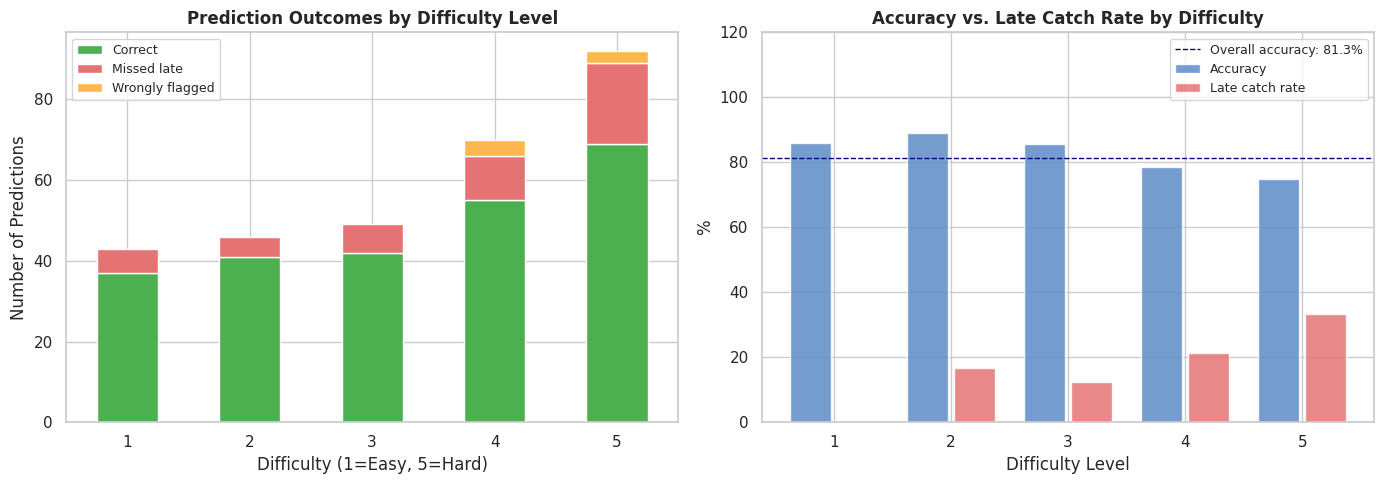

In [14]:
# Visualize difficulty audit
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

diff_counts = results.groupby(['difficulty', 'error_type']).size().unstack(fill_value=0)
for col in ['Correct', 'Missed late', 'Wrongly flagged']:
    if col not in diff_counts.columns:
        diff_counts[col] = 0
diff_counts = diff_counts[['Correct', 'Missed late', 'Wrongly flagged']]

diff_counts.plot(
    kind='bar', stacked=True, ax=axes[0],
    color=['#4CAF50', '#E57373', '#FFB74D'], edgecolor='white'
)
axes[0].set_title('Prediction Outcomes by Difficulty Level', fontweight='bold')
axes[0].set_xlabel('Difficulty (1=Easy, 5=Hard)')
axes[0].set_ylabel('Number of Predictions')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(fontsize=9)

acc_by_diff = results.groupby('difficulty')['correct'].mean()
late_by_diff = results[results[TARGET]==0].groupby('difficulty').apply(
    lambda g: (g['predicted'] == 0).mean()
)

x = np.array(sorted(results['difficulty'].unique()))
axes[1].bar(x - 0.2, acc_by_diff.values * 100, width=0.35,
            label='Accuracy', color='#5C8BC7', alpha=0.85)
# Only plot late recall where we have late submissions in test set
late_x = [d for d in x if d in late_by_diff.index]
late_y = [late_by_diff[d] * 100 for d in late_x]
axes[1].bar(np.array(late_x) + 0.2, late_y, width=0.35,
            label='Late catch rate', color='#E57373', alpha=0.85)
axes[1].axhline(overall_acc * 100, color='navy', linestyle='--',
                linewidth=1, label=f'Overall accuracy: {overall_acc*100:.1f}%')
axes[1].set_xlabel('Difficulty Level')
axes[1].set_ylabel('%')
axes[1].set_title('Accuracy vs. Late Catch Rate by Difficulty', fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'{d}' for d in x])
axes[1].set_ylim(0, 120)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

### Finding 2: The Hardest Assignments Hold the Most Misses

Accuracy is highest for easier assignments (86–89% at levels 1–3) and lowest for the hardest (75.0% at level 5).

Difficulty-5 assignments also have by far the most late submissions: 30 of 92. The model catches a larger share here (10 of 30) than at any other level, but because so many students are late, the misses pile up: **20 of the model's 49 missed late submissions come from difficulty 5 alone**, and difficulty 4 adds 11 more.

This means the model is **least accurate precisely when the stakes are highest**: when students are attempting the hardest material and most likely to fall behind.

## TO-DO:

> 📝 **Reflection:** If a system is most likely to fail for the students facing the hardest work, what does that mean for who the system actually serves? How does this relate to Catholic social teaching's preferential option for those who are most vulnerable?
>
> *(Answer in 3–5 complete sentences. Answer both questions, and use at least one number from the difficulty audit above.)*

<details>
<summary>💡 Hint</summary>

- This prompt has **two questions**. Answer both.
- Look at difficulty 5 in the audit table. How many assignments were late, and how many did the model miss? Compare that with the easier levels.
- Ask yourself: which students would get the most from an early warning, and are those the students the model helps most?
- The **preferential option for the poor and vulnerable** means giving special care to the people most in need, not the people who are already doing fine. Who is most "vulnerable" in this homework setting?

</details>

*For this data set, the accuracy that one would get would be 78.7%.  For the model to be useful, it must be greater than 78.7%.  For difficulty tier 4, the accuracy is 78.6%, and for difficulty tier #5, the accuracy is even lower with 75.0%.  Further, the model catches no more than 30% of the actually late assignments.  What this all means for the students that the model predicts, the model is worse than just guessing, and being of very little using in catching the important late assignments.  The students recieve little benefit from the model in the cases of difficult assignments.

If we consider students to be more "vulnerable" in the case of difficult assignments, then this model is an example of what Catholic social teaching condemns as a tool for re-enforcing the strength of the strong.  The model is more accurate for less important cases and less accurate for more important cases.*

---

## Part 4: The Most Important Audit — Prior Completion Rate Tier

This is the bias audit that matters most. We categorized students into four tiers based on their historical completion rate. Let's examine whether the model performs equally for students in each tier.

In [15]:
# Create completion rate tiers
# Define the bins and labels ONCE so every table and chart uses the same tiers.
TIER_BINS   = [0, 0.60, 0.75, 0.90, 1.01]
TIER_LABELS = ['<60%', '60–75%', '75–90%', '>90%']
tier_order  = TIER_LABELS

def add_prior_tier(frame):
    """Adds a 'prior_tier' column. include_lowest=True keeps a student with
    exactly 0% prior completion in the lowest tier instead of dropping them."""
    frame['prior_tier'] = pd.cut(
        frame['prior_completion_rate'],
        bins=TIER_BINS, labels=TIER_LABELS, include_lowest=True
    )
    return frame

df = add_prior_tier(df)            # full dataset: the ground truth
results = add_prior_tier(results)  # test set: what the model predicted

# Full dataset late rate by tier — what is the ground truth?
full_tier_stats = df.groupby('prior_tier', observed=True).agg(
    n=('completed_on_time', 'count'),
    actual_late_rate=('completed_on_time', lambda x: 1 - x.mean()),
    avg_prior_grade=('prior_avg_grade', 'mean')
).reset_index()

print('=== Ground Truth: Late Rate by Prior Completion Tier (full dataset) ===')
print(full_tier_stats.round(3).to_string(index=False))
print()
print('Students with lower prior completion rates are MUCH more likely to be late.')
print('This is the pattern the model has learned — and the pattern that creates the bias.')

=== Ground Truth: Late Rate by Prior Completion Tier (full dataset) ===
prior_tier   n  actual_late_rate  avg_prior_grade
      <60% 236             0.487           74.683
    60–75% 197             0.284           84.644
    75–90% 430             0.209           87.204
      >90% 637             0.091           93.081

Students with lower prior completion rates are MUCH more likely to be late.
This is the pattern the model has learned — and the pattern that creates the bias.


In [16]:
# Audit by completion rate tier
tier_audit = []
for tier in tier_order:
    subset = results[results['prior_tier'] == tier]
    row = audit_group(subset, tier)
    if row:
        tier_audit.append(row)

tier_df = pd.DataFrame(tier_audit)
print('=== Model Performance by Prior Completion Rate Tier ===')
print(tier_df.to_string(index=False))
print()
print('=== Where the Numbers Come From ===')
show_calculations(tier_audit)
print()

# Highlight the disparity
accs = [r['Accuracy'] for r in tier_audit]
if accs:
    gap = max(accs) - min(accs)
    print(f'Accuracy range across tiers: {min(accs):.3f} to {max(accs):.3f}')
    print(f'Accuracy gap: {gap:.3f} ({gap * 100:.1f} percentage points)')

=== Model Performance by Prior Completion Rate Tier ===
 Group   n  Actual late  Late caught  Late missed  On-time flagged  On-time correct  Accuracy  Late recall  False flag rate  Avg predicted prob
  <60%  43           20           12            8                6               17     0.674        0.600            0.261               0.523
60–75%  46           16            3           13                1               29     0.696        0.188            0.033               0.739
75–90%  86           17            0           17                0               69     0.802        0.000            0.000               0.832
  >90% 125           11            0           11                0              114     0.912        0.000            0.000               0.887

=== Where the Numbers Come From ===
 Group        Accuracy   Late recall False flag rate
  <60%   29/43 = 0.674 12/20 = 0.600    6/23 = 0.261
60–75%   32/46 = 0.696  3/16 = 0.188    1/30 = 0.033
75–90%   69/86 = 0.802  0/17

### Seeing the Confusion Matrix for Each Tier

The table gives the counts; a picture makes the pattern easier to spot. Below is one confusion matrix per tier. Each box shows the **count** and, in parentheses, the **percentage of that row**. Read each grid like this:

- **Top-left** (actually late, predicted late): late students the model caught. Its percentage is the **late recall**.
- **Top-right** (actually late, predicted on time): late students the model missed.
- **Bottom-left** (actually on time, predicted late): on-time students wrongly flagged. Its percentage is the **false flag rate**.
- **Bottom-right** (actually on time, predicted on time): on-time students the model got right.

Shading follows the row percentage, not the raw count, so a tier with 125 students doesn't wash out a tier with 43. Watch the left column of each grid as you move from the weakest tier to the strongest.

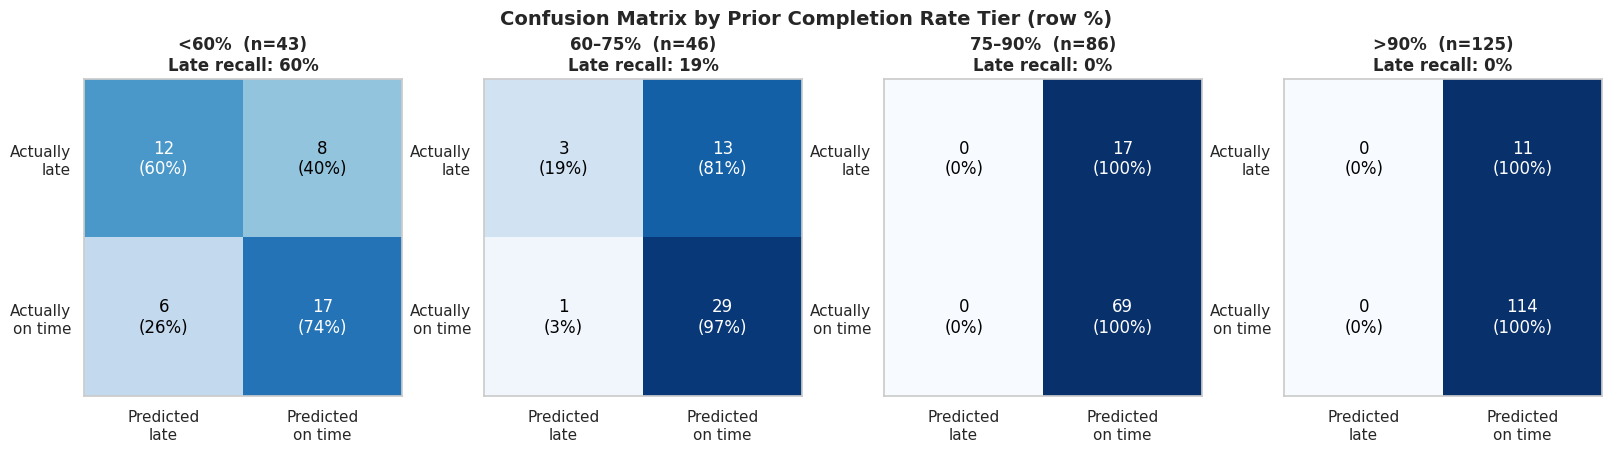

In [17]:
# Confusion matrix for each prior completion tier
fig, axes = plt.subplots(1, len(tier_order), figsize=(16, 4.4), constrained_layout=True)

for ax, tier in zip(axes, tier_order):
    subset = results[results['prior_tier'] == tier]

    # Rows: actually late / actually on time. Columns: predicted late / predicted on time.
    # Categorical with both values keeps the "predicted late" column even when it is all zeros.
    cm = pd.crosstab(
        pd.Categorical(subset[TARGET], categories=[0, 1]),
        pd.Categorical(subset['predicted'], categories=[0, 1]),
        dropna=False
    ).values

    row_totals = cm.sum(axis=1, keepdims=True)
    row_pct = np.divide(cm, row_totals, out=np.zeros(cm.shape), where=row_totals > 0)

    ax.imshow(row_pct, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({row_pct[i, j]:.0%})',
                    ha='center', va='center', fontsize=12,
                    color='white' if row_pct[i, j] > 0.5 else 'black')

    ax.set_xticks([0, 1], ['Predicted\nlate', 'Predicted\non time'])
    ax.set_yticks([0, 1], ['Actually\nlate', 'Actually\non time'])
    ax.grid(False)
    ax.set_title(f'{tier}  (n={cm.sum()})\nLate recall: {row_pct[0, 0]:.0%}', fontweight='bold')

fig.suptitle('Confusion Matrix by Prior Completion Rate Tier (row %)', fontsize=14, fontweight='bold')
plt.show()

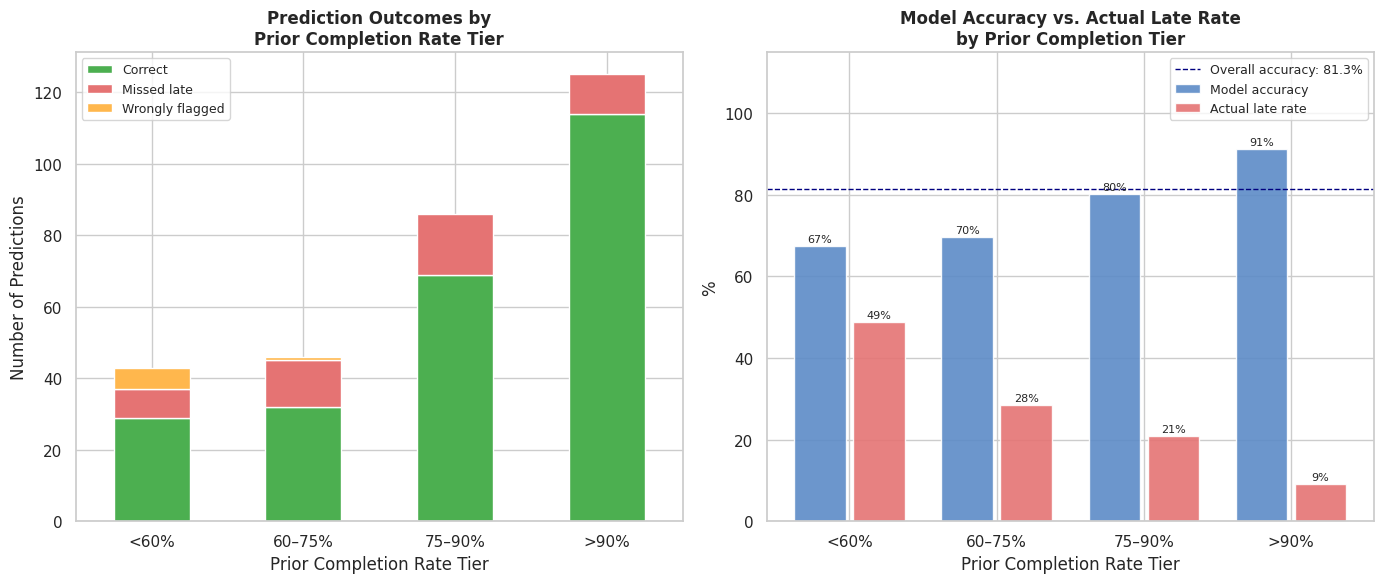

In [18]:
# Visualize the performance disparity across tiers
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Accuracy and actual late rate by tier
tier_counts = results.groupby(['prior_tier', 'error_type'], observed=True).size().unstack(fill_value=0)
for col in ['Correct', 'Missed late', 'Wrongly flagged']:
    if col not in tier_counts.columns:
        tier_counts[col] = 0
tier_counts = tier_counts[['Correct', 'Missed late', 'Wrongly flagged']]

tier_counts.plot(
    kind='bar', stacked=True, ax=axes[0],
    color=['#4CAF50', '#E57373', '#FFB74D'], edgecolor='white'
)
axes[0].set_title('Prediction Outcomes by\nPrior Completion Rate Tier', fontweight='bold')
axes[0].set_xlabel('Prior Completion Rate Tier')
axes[0].set_ylabel('Number of Predictions')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(fontsize=9)

# Right: Accuracy vs. actual late rate — the gap that reveals the problem
x = np.arange(len(tier_order))
test_acc_by_tier = results.groupby('prior_tier', observed=True)['correct'].mean()
test_late_by_tier = df.groupby('prior_tier', observed=True)['completed_on_time'].apply(
    lambda s: 1 - s.mean()
)

acc_vals = [test_acc_by_tier.get(t, 0) * 100 for t in tier_order]
late_vals = [test_late_by_tier.get(t, 0) * 100 for t in tier_order]

axes[1].bar(x - 0.2, acc_vals, width=0.35,
            label='Model accuracy', color='#5C8BC7', alpha=0.9)
axes[1].bar(x + 0.2, late_vals, width=0.35,
            label='Actual late rate', color='#E57373', alpha=0.9)
axes[1].axhline(overall_acc * 100, color='navy', linestyle='--',
                linewidth=1, label=f'Overall accuracy: {overall_acc*100:.1f}%')
axes[1].set_xticks(x)
axes[1].set_xticklabels(tier_order)
axes[1].set_xlabel('Prior Completion Rate Tier')
axes[1].set_ylabel('%')
axes[1].set_title('Model Accuracy vs. Actual Late Rate\nby Prior Completion Tier', fontweight='bold')
axes[1].set_ylim(0, 115)
axes[1].legend(fontsize=9)

for i, (a, l) in enumerate(zip(acc_vals, late_vals)):
    axes[1].text(i - 0.2, a + 1, f'{a:.0f}%', ha='center', fontsize=8)
    axes[1].text(i + 0.2, l + 1, f'{l:.0f}%', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

### Finding 3: A 24-Point Accuracy Gap, and Two Different Kinds of Unfairness

The audit reveals a clear performance disparity:

| Tier | Accuracy | Late caught | On-time wrongly flagged | What this means |
|------|----------|-------------|-------------------------|-----------------|
| **>90%** | 91% | 0 of 11 | 0 of 114 | Never flagged, so every late submission is missed |
| **75–90%** | 80% | 0 of 17 | 0 of 69 | Never flagged, so every late submission is missed |
| **60–75%** | 70% | 3 of 16 | 1 of 30 | Rarely flagged; misses 13 of 16 late submissions |
| **<60%** | 67% | 12 of 20 | 6 of 23 | Flagged often; catches most late students, but wrongly flags about 1 in 4 on-time students |

The model is most accurate for students with the strongest records and least accurate for students with the weakest. But the table shows two different kinds of unfairness:

1. **Students with strong records are invisible when they struggle.** Not one of the 211 test students at 75% or above was flagged, so all 28 of their late submissions were missed.
2. **Students with weak records are suspected even when they do fine.** Every flag the model raised went to students below 75%, including all 7 false alarms. Six of those 7 landed on students below 60%.

The next section looks at why.

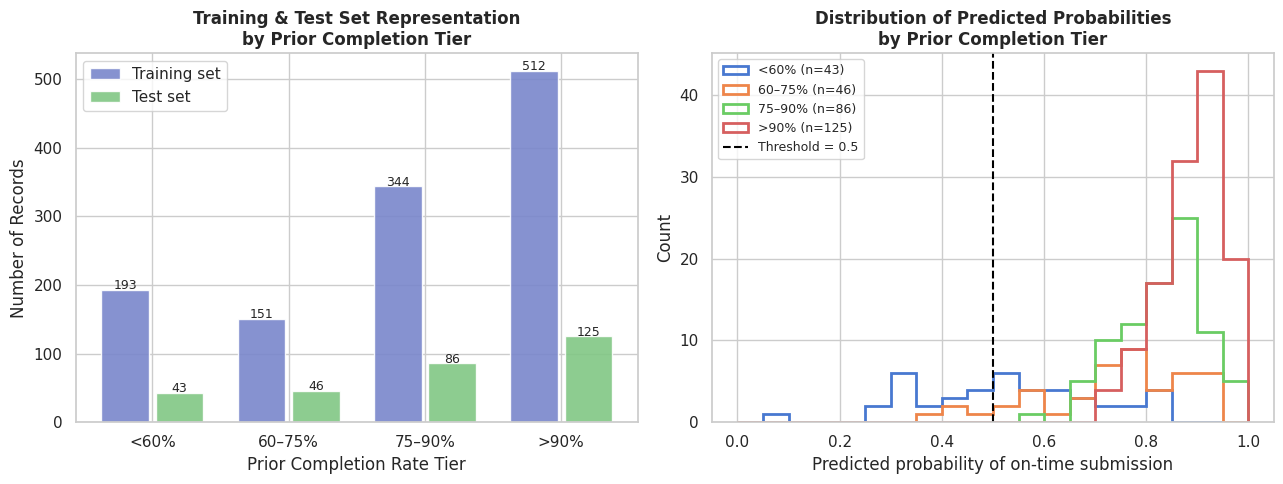

In [19]:
# How represented is each tier in the training data?
train_df = df.loc[X_train.index].copy()
# train_df already has 'prior_tier': it was copied from df after the tiers were added

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Training data representation
train_tier_counts = train_df['prior_tier'].value_counts()[tier_order]
test_tier_counts  = results['prior_tier'].value_counts().reindex(tier_order, fill_value=0)

x = np.arange(len(tier_order))
axes[0].bar(x - 0.2, train_tier_counts.values, width=0.35,
            label='Training set', color='#7986CB', alpha=0.9)
axes[0].bar(x + 0.2, test_tier_counts.values, width=0.35,
            label='Test set', color='#81C784', alpha=0.9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tier_order)
axes[0].set_xlabel('Prior Completion Rate Tier')
axes[0].set_ylabel('Number of Records')
axes[0].set_title('Training & Test Set Representation\nby Prior Completion Tier', fontweight='bold')
axes[0].legend()
for i, (tr, te) in enumerate(zip(train_tier_counts.values, test_tier_counts.values)):
    axes[0].text(i - 0.2, tr + 0.5, str(tr), ha='center', fontsize=9)
    axes[0].text(i + 0.2, te + 0.5, str(te), ha='center', fontsize=9)

# Predicted probability distribution by tier
for tier in tier_order:
    subset = results[results['prior_tier'] == tier]['prob_on_time']
    if len(subset) > 0:
        axes[1].hist(subset, bins=np.linspace(0, 1, 21), histtype='step', linewidth=2,
                     label=f'{tier} (n={len(subset)})')
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Threshold = 0.5')
axes[1].set_xlabel('Predicted probability of on-time submission')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of Predicted Probabilities\nby Prior Completion Tier', fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

### The Root Cause: The Model Judges Students by Their Past

The chart on the left shows how many records each tier has. The lower tiers are smaller, but not tiny: 193 of the 1,200 training records (16%) are below 60%, so the model has real examples of struggling students to learn from. With this larger dataset, underrepresentation is **not** the main problem.

The chart on the right shows the real cause. The model leans hardest on `prior_completion_rate`, so a student's history largely decides their score:

- **Students above 90%:** every predicted probability is at least 0.725, far above the 0.5 threshold. No matter what happens this week, the model cannot flag them.
- **Students below 60%:** scores average 0.52, right at the threshold. The model flags 18 of these 43 students, catching 12 who were late but also wrongly flagging 6 who turned their work in on time.

Two things are true at once. The pattern is real: in the full dataset, students below 60% were late 49% of the time, compared with 9% for students above 90%. But a group whose outcomes are close to 50/50 is the hardest group to predict, and the model treats a strong past record as a guarantee. This is a general problem in AI: **a model trained on people's histories will tend to confirm those histories**, trusting those with good records and doubting those without.

## TO-DO:

> 🤔 **Think about it:** *Magnifica Humanitas* (no. 80) warns that in the digital age, justice demands we prevent new forms of exclusion — including algorithms that perpetuate prejudice and discrimination for underrepresented groups. Is the bias we found here intentional? Does it matter if it wasn't intentional?
>
> *(Answer in 3–5 complete sentences. Answer both questions, and use at least one number from the representation chart above.)*

<details>
<summary>💡 Hint</summary>

- This prompt has **two questions**: *Was it intentional?* and *Does it matter if it wasn't?* Answer both.
- For the first: did anyone write code that says "distrust weak students"? Look at "The Root Cause" section above. Where did the pattern come from?
- For the second: imagine you are an on-time student with a weak record who got flagged anyway. Does it change anything for you whether the model *meant* to do it?
- The prompt asks for a number from the **representation chart** (the left chart). How many training records are below 60%? Notice what the notebook concludes about whether under-representation is the main problem here.

</details>

*The bias that we found here was that the algorithm was more accurate in late submissions for weaker students (<75% prior completion) and on_time submissions for stronger students (>75% prior completion), and less accurate for on_time submissions for weak students and late submissions for strong students.  The model guessed that weak students would be worse, and strong students would be better.  Whether this bias was intentional or not, this is the bias that we want.  We want the model to err on the side of thinking a submission will be late for weak students, and err on the side of thinking a submission will be on-time for a strong student. The bias in the AI model is not necessarily wrong, but it must be made intentionally, and err on the side of helping the weak more.  Bias in an AI model must always be intentional.*

---

## Part 5: Per-Student Bias Analysis

Aggregate statistics across tiers can hide individual patterns. Let's look at which specific students are consistently mislabeled.

In [20]:
# Per-student performance on test set
student_audit = results.groupby('student_id').apply(
    lambda g: pd.Series({
        'n_predictions': len(g),
        'accuracy': g['correct'].mean(),
        'missed_late': ((g['predicted']==1) & (g[TARGET]==0)).sum(),
        'wrongly_flagged': ((g['predicted']==0) & (g[TARGET]==1)).sum(),
        'actual_late_rate': (g[TARGET]==0).mean(),
        'avg_prob_predicted': g['prob_on_time'].mean(),
        'prior_completion_rate': g['prior_completion_rate'].mean(),
        'prior_avg_grade': g['prior_avg_grade'].mean(),
    })
).reset_index()

# Students with at least 2 predictions for reliability
student_audit_filtered = student_audit[student_audit['n_predictions'] >= 2].copy()

print('=== Students with Worst Model Performance (≥2 predictions) ===')
worst = student_audit_filtered.sort_values('accuracy').head(10)
print(worst[['student_id','n_predictions','accuracy','missed_late',
              'wrongly_flagged','actual_late_rate',
              'prior_completion_rate','avg_prob_predicted']].round(3).to_string(index=False))

=== Students with Worst Model Performance (≥2 predictions) ===
student_id  n_predictions  accuracy  missed_late  wrongly_flagged  actual_late_rate  prior_completion_rate  avg_prob_predicted
      S124            2.0     0.000          2.0              0.0             1.000                  0.815               0.775
      S135            2.0     0.000          2.0              0.0             1.000                  0.470               0.560
      S144            2.0     0.000          2.0              0.0             1.000                  0.975               0.830
      S164            3.0     0.000          1.0              2.0             0.333                  0.443               0.481
      S165            2.0     0.000          2.0              0.0             1.000                  0.750               0.896
      S199            2.0     0.000          2.0              0.0             1.000                  0.700               0.673
      S143            3.0     0.333          1.0

/tmp/ipykernel_1148/263190554.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  student_audit = results.groupby('student_id').apply(


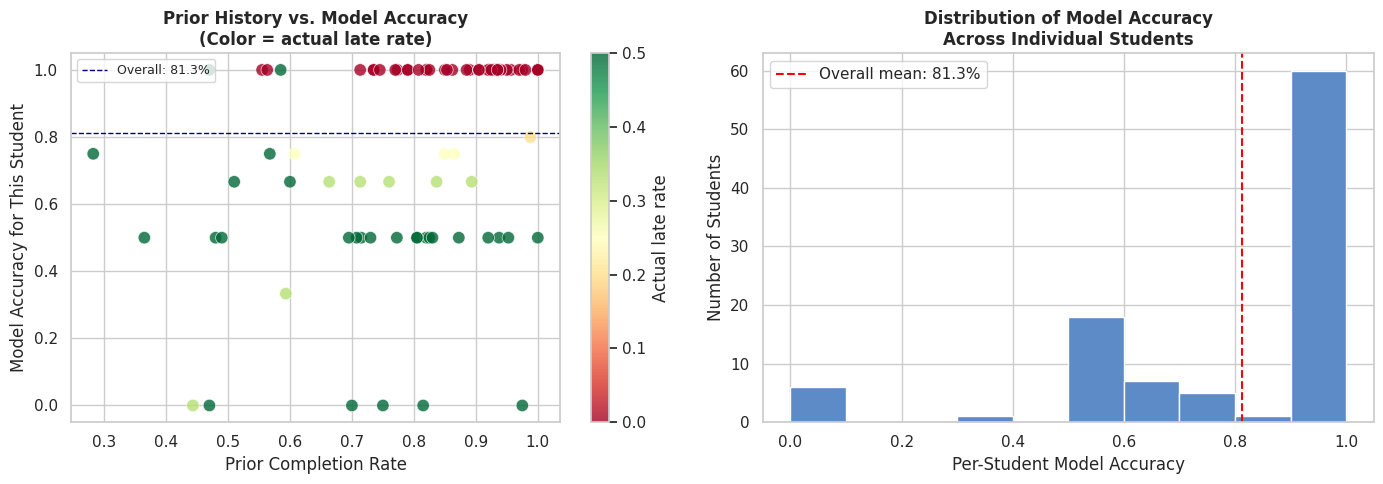

Students where model accuracy < 70%: 32
Students where model accuracy = 100%: 60


In [21]:
# Scatter: prior completion rate vs. model accuracy for each student
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc = axes[0].scatter(
    student_audit_filtered['prior_completion_rate'],
    student_audit_filtered['accuracy'],
    c=student_audit_filtered['actual_late_rate'],
    cmap='RdYlGn', vmin=0, vmax=0.5,
    s=80, alpha=0.8, edgecolors='white', linewidths=0.5
)
plt.colorbar(sc, ax=axes[0], label='Actual late rate')
axes[0].axhline(overall_acc, color='navy', linestyle='--',
                linewidth=1, label=f'Overall: {overall_acc*100:.1f}%')
axes[0].set_xlabel('Prior Completion Rate')
axes[0].set_ylabel('Model Accuracy for This Student')
axes[0].set_title('Prior History vs. Model Accuracy\n(Color = actual late rate)', fontweight='bold')
axes[0].legend(fontsize=9)

# Histogram of per-student accuracy
axes[1].hist(student_audit_filtered['accuracy'], bins=10,
             color='#5C8BC7', edgecolor='white')
axes[1].axvline(overall_acc, color='red', linestyle='--',
                linewidth=1.5, label=f'Overall mean: {overall_acc*100:.1f}%')
axes[1].set_xlabel('Per-Student Model Accuracy')
axes[1].set_ylabel('Number of Students')
axes[1].set_title('Distribution of Model Accuracy\nAcross Individual Students', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'Students where model accuracy < 70%: {(student_audit_filtered["accuracy"] < 0.70).sum()}')
print(f'Students where model accuracy = 100%: {(student_audit_filtered["accuracy"] == 1.0).sum()}')

### Finding 4: Some Students Are Almost Always Mislabeled

The scatter plot shows the pattern: students with higher prior completion rates generally sit higher on the chart. Among the 98 students with at least two predictions, the model averaged 86% accuracy for students at or above 75% prior completion, but only 64% for students below 75%. Most of the errors are **missed late submissions**: 46 of the 52 mistakes for these students.

Six students were wrong on every prediction, and three of them had strong records (prior completion of 75% or higher, one as high as 97.5%). The model trusted their past, and their past didn't tell the whole story.

These are real people (or simulated ones). If this model were deployed in a school:

- A reliable student who hit a hard week would receive no alert: no early check-in, no additional support
- A student with a weaker record would be flagged even when doing fine, and might face unnecessary attention or scrutiny
- The teacher would be told to watch the students with weak histories, and would rarely hear about anyone else

The model would, in practice, confirm what the teacher already believed about each student, rather than revealing who actually needs help this week.

---

## Part 6: Comparing Feature Sets — Does Removing History Help?

In Module 2, you were asked whether to include student history, such as `prior_completion_rate` and `prior_deadline_usage`. Module 3 showed that `prior_completion_rate` is the most influential feature. Now we can ask the bias question directly: **does removing these history-based features reduce the performance disparity?**

In [22]:
# Train the conservative model (no student history)
X_cons = df[CONSERVATIVE_FEATURES]

Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(
    X_cons, y, test_size=0.2, random_state=42, stratify=y
)
sc_c = StandardScaler()
lr_c = LogisticRegression(random_state=42, max_iter=1000)
lr_c.fit(sc_c.fit_transform(Xtr_c), ytr_c)
yp_c = lr_c.predict(sc_c.transform(Xte_c))

results_cons = df.loc[Xte_c.index].copy()
results_cons['predicted'] = yp_c
results_cons['correct'] = (results_cons['predicted'] == results_cons[TARGET]).astype(int)
# results_cons already has 'prior_tier': it was copied from df after the tiers were added

print('=== Bias Comparison: Full Model vs. Conservative Model ===')
print()
print(f'{"Tier":<12} {"Full accuracy":>16} {"Cons accuracy":>16} {"Change":>10}')
print('-' * 56)

for tier in tier_order:
    full_sub = results[results['prior_tier'] == tier]
    cons_sub = results_cons[results_cons['prior_tier'] == tier]

    full_acc = full_sub['correct'].mean() if len(full_sub) > 0 else float('nan')
    cons_acc = cons_sub['correct'].mean() if len(cons_sub) > 0 else float('nan')
    change = cons_acc - full_acc

    print(f'{tier:<12} {full_acc*100:>14.1f}%  {cons_acc*100:>14.1f}%  {change*100:>+8.1f}pp')

print()
print(f'Overall — Full:         {accuracy_score(y_test, y_pred)*100:.1f}%')
print(f'Overall — Conservative: {accuracy_score(yte_c, yp_c)*100:.1f}%')

=== Bias Comparison: Full Model vs. Conservative Model ===

Tier            Full accuracy    Cons accuracy     Change
--------------------------------------------------------
<60%                   67.4%            53.5%     -14.0pp
60–75%                 69.6%            65.2%      -4.3pp
75–90%                 80.2%            80.2%      +0.0pp
>90%                   91.2%            91.2%      +0.0pp

Overall — Full:         81.3%
Overall — Conservative: 78.7%


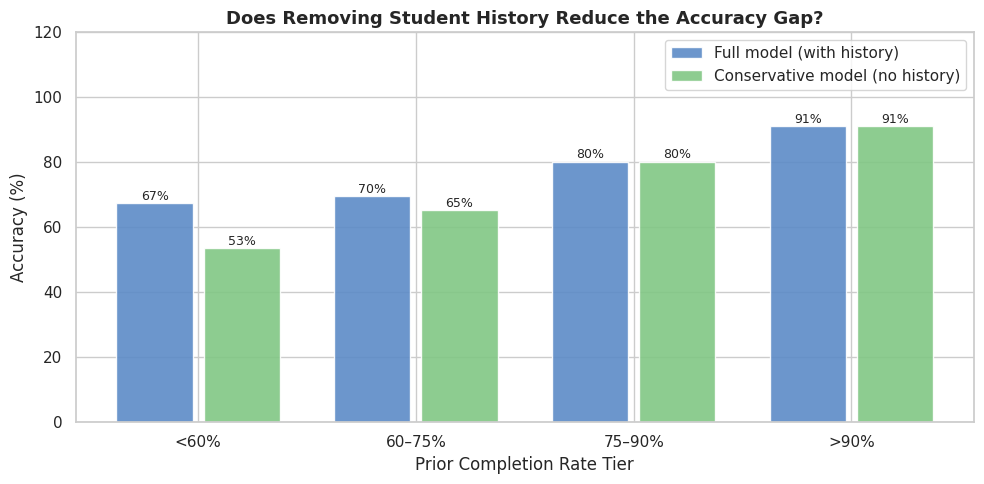

In [23]:
# Visualize the accuracy comparison
full_accs  = [results[results['prior_tier']==t]['correct'].mean() * 100 for t in tier_order]
cons_accs  = [results_cons[results_cons['prior_tier']==t]['correct'].mean() * 100 for t in tier_order]

x = np.arange(len(tier_order))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - 0.2, full_accs, width=0.35, label='Full model (with history)',
       color='#5C8BC7', alpha=0.9)
ax.bar(x + 0.2, cons_accs, width=0.35, label='Conservative model (no history)',
       color='#81C784', alpha=0.9)
ax.set_xticks(x)
ax.set_xticklabels(tier_order)
ax.set_xlabel('Prior Completion Rate Tier')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Does Removing Student History Reduce the Accuracy Gap?', fontsize=13, fontweight='bold')
ax.set_ylim(0, 120)
ax.legend()
for i, (f, c) in enumerate(zip(full_accs, cons_accs)):
    ax.text(i - 0.2, f + 1, f'{f:.0f}%', ha='center', fontsize=9)
    ax.text(i + 0.2, c + 1, f'{c:.0f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

### Finding 5: Removing History Makes the Gap Worse

Without `prior_completion_rate` and `prior_deadline_usage`, the model flags **no one at all**. It predicts "on time" for all 300 test students, so its overall accuracy (78.7%) is exactly the same as always guessing "on time."

Each tier's accuracy becomes simply the share of its students who were on time. For students below 60%, accuracy drops from 67.4% to 53.5%, while the top two tiers don't change. The gap between the best and worst tiers grows from 24 points to 38.

This is a hard lesson: **hiding information about students does not make a model fair.** The history-blind model treats every student the same, and so it fails most the students who are late most often. The full model is more useful, but it earns that usefulness by judging students on their past.

Neither version is fair. Genuinely fair AI requires more than choosing features:
- Features that describe a student's **current** situation, not only their past
- A person who reviews every flag before anything happens to a student
- Or, for some applications, honest acknowledgment that the AI should not be used for consequential decisions about individuals


---

## Part 7: Producing the Bias Audit Report

In [24]:
# Formal bias audit report
print('=' * 65)
print('BIAS AUDIT REPORT — Module 4')
print('Project: Predicting On-Time Homework Submission')
print('=' * 65)
print()
print(f'Overall test accuracy:          {overall_acc*100:.1f}%')
print()

print('PERFORMANCE BY PRIOR COMPLETION RATE TIER:')
print(f'  {"Tier":<12} {"n":>5} {"Accuracy":>10} {"Late caught":>12} {"Late total":>12}')
print('  ' + '-' * 48)
for tier in tier_order:
    sub = results[results['prior_tier'] == tier]
    if len(sub) == 0: continue
    acc = sub['correct'].mean()
    late_total = (sub[TARGET] == 0).sum()
    late_caught = ((sub['predicted'] == 0) & (sub[TARGET] == 0)).sum()
    print(f'  {tier:<12} {len(sub):>5} {acc*100:>9.1f}%  {late_caught:>8}/{late_total:<8}')

print()
print('KEY FINDINGS:')
print('  1. Accuracy is lowest for students with the lowest prior completion rates')
print('  2. Students at 75% or above are never flagged: all of their late submissions are missed')
print('  3. Every flag, including every false alarm, goes to students below 75%')
print('  4. Root cause: the model leans on prior_completion_rate, judging students by their past')
print('  5. Removing history features makes the accuracy gap worse, not better')
print()
print('FAIRNESS METRICS:')
tier_accs = {t: results[results['prior_tier']==t]['correct'].mean() for t in tier_order
             if len(results[results['prior_tier']==t]) > 0}
worst_tier = min(tier_accs, key=tier_accs.get)
best_tier  = max(tier_accs, key=tier_accs.get)
print(f'  Max accuracy gap across tiers: {(tier_accs[best_tier]-tier_accs[worst_tier])*100:.1f} percentage points')
print(f'  Tier with worst performance: {worst_tier} ({tier_accs[worst_tier]*100:.1f}% accurate)')
print(f'  Tier with best performance:  {best_tier} ({tier_accs[best_tier]*100:.1f}% accurate)')
print()


BIAS AUDIT REPORT — Module 4
Project: Predicting On-Time Homework Submission

Overall test accuracy:          81.3%

PERFORMANCE BY PRIOR COMPLETION RATE TIER:
  Tier             n   Accuracy  Late caught   Late total
  ------------------------------------------------
  <60%            43      67.4%        12/20      
  60–75%          46      69.6%         3/16      
  75–90%          86      80.2%         0/17      
  >90%           125      91.2%         0/11      

KEY FINDINGS:
  1. Accuracy is lowest for students with the lowest prior completion rates
  2. Students at 75% or above are never flagged: all of their late submissions are missed
  3. Every flag, including every false alarm, goes to students below 75%
  4. Root cause: the model leans on prior_completion_rate, judging students by their past
  5. Removing history features makes the accuracy gap worse, not better

FAIRNESS METRICS:
  Max accuracy gap across tiers: 23.8 percentage points
  Tier with worst performance: <60% 

## TO-DO:

### RECOMMENDATION:

> 📝 **Reflection:** You have now found bias in the model that cannot be fully fixed by changing which features you use. What does this mean for whether the model should be deployed in a real school? Write your recommendation.
>
> *(Answer in 3–5 complete sentences and use at least one number from the report above. You may start from this:)*
>
> *I recommend that this model should be used in a real school because the objections that were given to the biased AI do not actually seem like red flags. The bias audit showed that the model catches 0% of late submissions for students with a prior_completion rate of 75% or greater.  This should be more or less expected from the AI model given the data used.  Nowhere in the data does it indicate that a usually strong student is having a difficult week.  

> If the model were used, the teacher should make the final decision about each student because the teacher can know more about the student than what is included in the data.*

<details>
<summary>💡 Hint</summary>

- Pick **one** option: *should*, *should not*, or *should only under certain conditions*. Any choice can earn full credit if your reasons and evidence support it.
- If you choose "only under certain conditions," name the conditions. Vague conditions like "if it's careful" won't be enough.
- Pick your number from the report: the accuracy gap between tiers, how many late submissions were missed for students at 75% or above, or where the false alarms went.
- For the last blank, think about *who knows the student*. What can a person notice about a student's week that the model's data can't see?

</details>

*[Write your response here. Be sure to follow the course's Student Writing Guidelines.]*

---

## Part 8: A Framework for Thinking About AI Fairness

The bias audit revealed a specific problem in a specific model. But the thinking tools we developed apply broadly. Before any AI system is deployed in a context that affects real people, it should be audited along these dimensions:

| Fairness Dimension | Question to Ask | How We Measured It |
|---|---|---|
| **Accuracy parity** | Is the model equally accurate across subgroups? | Accuracy by tier, type, difficulty |
| **Recall parity** | Does the model catch the target outcome equally across groups? | Late catch rate by tier |
| **Precision parity** | Does the model flag false positives equally across groups? | False flag rate by tier |
| **Representation** | Is every group adequately represented in training data? | Count by tier in training set |
| **Confidence calibration** | Is the model's confidence level trustworthy across groups? | Predicted probability distribution by tier |

### The Catholic Standard

*Magnifica Humanitas* (no. 109) states that to speak of social justice requires questioning the global distribution of power that decides who in fact can train these models and **who is merely subjected to them**. In the context of our homework model:

- Students with strong academic histories are **trusted automatically**: the model never flags them, not even the 28 who turned work in late
- Students with weaker histories are **subjected to the model's suspicion**: they receive every flag it raises, including all 7 false alarms
- Removing their history doesn't rescue them: the history-blind model simply helps no one

This is not an abstract philosophical concern. It is a measurable, documented pattern in the model you built. And it should change what you recommend about how — or whether — this model is deployed.

---

## Summary and What's Coming Next

### What You Accomplished in This Module

- Conducted a structured bias audit across assignment type, difficulty level, prior completion rate, and individual students
- Checked whether Module 3's findings held up on a dataset three times larger
- Discovered a 24-percentage-point accuracy gap between the highest- and lowest-performing student tiers
- Found that the model judges students by their past: students with strong records are never flagged, even when late, while students with weaker records receive every flag, including every false alarm
- Identified the root cause: heavy reliance on `prior_completion_rate`, combined with outcomes close to 50/50 for the lowest tier
- Tested whether removing history-based features reduces bias, and found it makes the gap worse (24 points to 38)
- Produced a formal bias audit report and grounded the findings in *Magnifica Humanitas*

### Coming in Module 5 (Classes 9–10)

Module 5 addresses the governance question: **given everything we have found, under what conditions — if any — should this model be deployed?** You will draft a data governance policy for the system, specifying who should have access to predictions, what human oversight mechanisms must be in place, what disclosures students and families deserve, and what the conditions for revoking the system would be.

This will form the foundation of your final project presentation in Class 13.

---

> **A thought to carry forward:** *Magnifica Humanitas* (no. 102) says AI systems can cause injustice that "goes unnoticed" because it is cloaked in a veneer of neutrality. The bias you found in Module 4 would be invisible if you had only looked at the overall accuracy number. It took a deliberate audit — the decision to look — to find it. Most deployed AI systems have never been subjected to this kind of scrutiny. Who, in your view, is responsible for making sure they are?